# ODE Systems, Harmonic Oscillators, and Multivariable Newton Solvers

## 1. Theory Overview
- **Nuclear Decay:** $\frac{dN}{dt} = -\lambda N$. Explicit Euler stable if $\Delta t \le \frac{2}{\lambda}$; Implicit Euler is unconditionally stable.
- **Harmonic Oscillators:** $m \ddot{x} + \gamma \dot{x} + k x = 0$. Simple Euler pumps energy into periodic orbits; Euler-Cromer is symplectic; RK4 provides $\mathcal{O}(\Delta t^4)$ precision.
- **Nonlinear Phase Plane:** $\dot{\mathbf{X}} = \mathbf{f}(\mathbf{X})$, fixed points where $\mathbf{f}(\mathbf{X}^*) = \mathbf{0}$, classification by Jacobian eigenvalues.
- **Multivariable Newton-Raphson:** $\mathbf{x}_{k+1} = \mathbf{x}_k - [\mathbf{J}(\mathbf{x}_k)]^{-1}\mathbf{F}(\mathbf{x}_k)$.

## 2. EXACT CODE FROM QUIZ 2 REFERENCE PDF (Section 5.1)
Nuclear Decay Explicit vs. Implicit Euler stability comparison with $\Delta t = 22.0 > 2/\lambda = 20.0$.

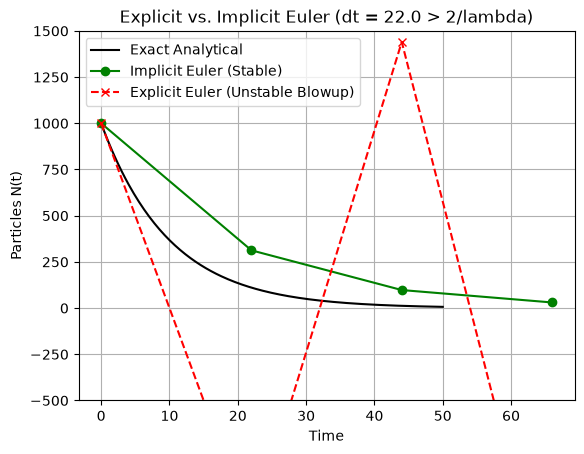

In [7]:
import numpy as np
import matplotlib.pyplot as plt

N0 = 1000.0; lamb = 0.1; t_end = 50.0
# Characteristic timescale tau = 1/lamb = 10.0
# Stability limit for explicit Euler: dt <= 2/lamb = 20.0

dt_unstable = 22.0  # Exceeds explicit stability limit!
t_unstable = np.arange(0, t_end + dt_unstable, dt_unstable)

N_exp = np.zeros(len(t_unstable)); N_exp[0] = N0
N_imp = np.zeros(len(t_unstable)); N_imp[0] = N0

for i in range(len(t_unstable) - 1):
    N_exp[i+1] = N_exp[i] * (1.0 - lamb * dt_unstable)
    N_imp[i+1] = N_imp[i] / (1.0 + lamb * dt_unstable)

t_fine = np.linspace(0, t_end, 200)
plt.plot(t_fine, N0 * np.exp(-lamb * t_fine), 'k-', label='Exact Analytical')
plt.plot(t_unstable, N_imp, 'go-', label='Implicit Euler (Stable)')
plt.plot(t_unstable, N_exp, 'rx--', label='Explicit Euler (Unstable Blowup)')
plt.xlabel('Time'); plt.ylabel('Particles N(t)'); plt.ylim(-500, 1500)
plt.title(f'Explicit vs. Implicit Euler (dt = {dt_unstable} > 2/lambda)')
plt.legend(); plt.grid(True); plt.show()


## 3. EXACT CODE FROM QUIZ 2 REFERENCE PDF (Section 5.2)
SHM RK4 implementation for a damped harmonic oscillator with position plot and $(x, v)$ phase space trajectory.

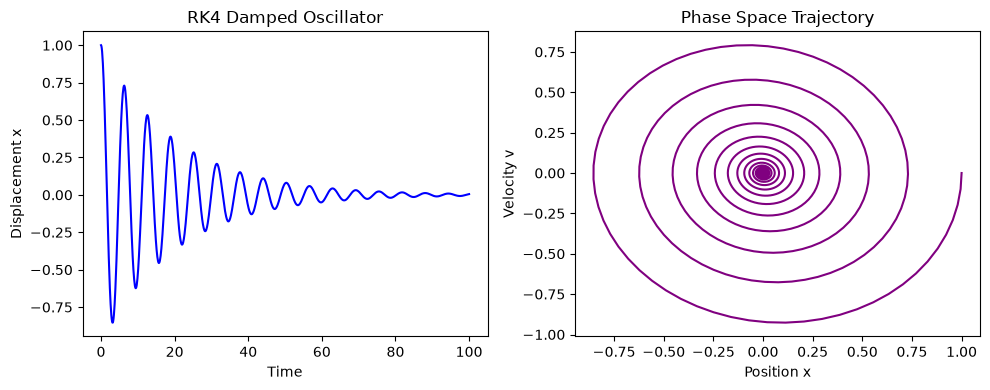

In [8]:
import numpy as np
import matplotlib.pyplot as plt

k = 1.0; m = 1.0; gamma = 0.1; dt = 0.1; t_end = 100.0
t = np.arange(0, t_end + dt, dt)
n = len(t)

# Solution array: row 0 = position x, row 1 = velocity v
y = np.zeros((2, n))
y[:, 0] = [1.0, 0.0] # Initial condition: x=1, v=0

for i in range(n - 1):
    k1 = np.array([
        y[1, i],
        -(gamma / m * y[1, i] + k / m * y[0, i])
    ])
    k2 = np.array([
        y[1, i] + 0.5 * dt * k1[1],
        -k / m * (y[0, i] + 0.5 * dt * k1[0]) - gamma / m * (y[1, i] + 0.5 * dt * k1[1])
    ])
    k3 = np.array([
        y[1, i] + 0.5 * dt * k2[1],
        -k / m * (y[0, i] + 0.5 * dt * k2[0]) - gamma / m * (y[1, i] + 0.5 * dt * k2[1])
    ])
    k4 = np.array([
        y[1, i] + dt * k3[1],
        -k / m * (y[0, i] + dt * k3[0]) - gamma / m * (y[1, i] + dt * k3[1])
    ])
    y[:, i + 1] = y[:, i] + dt * (k1 + 2*k2 + 2*k3 + k4) / 6.0

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(t, y[0, :], 'b-'); plt.xlabel('Time'); plt.ylabel('Displacement x'); plt.title('RK4 Damped Oscillator')
plt.subplot(1, 2, 2)
plt.plot(y[0, :], y[1, :], 'purple'); plt.xlabel('Position x'); plt.ylabel('Velocity v'); plt.title('Phase Space Trajectory')
plt.tight_layout(); plt.show()


## 4. EXACT CODE FROM QUIZ 2 REFERENCE PDF (Section 5.3)
2D Nonlinear System Phase Portrait: Competing species model with streamplot and fixed point markers.

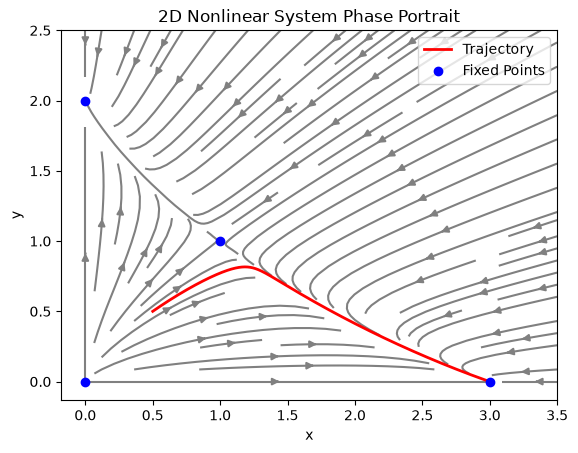

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# 2D Competing Species: dx/dt = x(3 - x - 2y), dy/dt = y(2 - y - x)
def f(X):
    x, y = X
    return np.array([x * (3 - x - 2*y), y * (2 - y - x)])

# Vector Field and Trajectory Simulation
dt = 0.01; steps = 2000
trajectory = np.zeros((2, steps))
trajectory[:, 0] = [0.5, 0.5] # Initial condition

for i in range(steps - 1):
    trajectory[:, i+1] = trajectory[:, i] + dt * f(trajectory[:, i])

X_grid, Y_grid = np.meshgrid(np.linspace(0, 3.5, 20), np.linspace(0, 2.5, 20))
U = X_grid * (3 - X_grid - 2*Y_grid)
V = Y_grid * (2 - Y_grid - X_grid)

plt.streamplot(X_grid, Y_grid, U, V, color='gray')
plt.plot(trajectory[0, :], trajectory[1, :], 'r-', lw=2, label='Trajectory')
plt.scatter([0, 3, 0, 1], [0, 0, 2, 1], color='blue', zorder=5, label='Fixed Points')
plt.xlabel('x'); plt.ylabel('y'); plt.title('2D Nonlinear System Phase Portrait'); plt.legend(); plt.show()


## 5. EXACT CODE FROM QUIZ 2 REFERENCE PDF (Section 5.4)
Multivariable Newton-Raphson system solver using explicit matrix inverse $\mathbf{x}_{k+1} = \mathbf{x}_k - [\mathbf{J}(\mathbf{x}_k)]^{-1}\mathbf{F}(\mathbf{x}_k)$.

In [10]:
import numpy as np

# System: f1 = x1 - x0^3 = 0,  f2 = x0^2 + x1^2 - 1 = 0
def func(x):
    return np.array([
        x[1] - x[0]**3,
        x[0]**2 + x[1]**2 - 1.0
    ])

def jacobian(x):
    return np.array([
        [-3.0 * x[0]**2, 1.0],
        [2.0 * x[0], 2.0 * x[1]]
    ], dtype=float)

# Initial guess
x = np.array([1.0, 2.0])
tol = 1e-8
max_iter = 100

for it in range(max_iter):
    F = func(x)
    J = jacobian(x)
    
    # Check convergence
    if np.linalg.norm(F) < tol:
        print(f"Converged in {it} iterations.")
        break
        
    # Newton update step using direct inverse formula: x_{k+1} = x_k - J^{-1} F
    step = np.linalg.inv(J) @ F
    x = x - step

print("Computed Root Vector x* =", x)
print("Residual F(x*) =", func(x))


Converged in 5 iterations.
Computed Root Vector x* = [0.82603136 0.56362416]
Residual F(x*) = [-1.89749327e-10  9.58302326e-11]


## 6. PROFESSOR'S IN-CLASS CODE: Newton's Method with Gaussian Elimination (from `Notes/Newton_SOE.ipynb`)
This is the code as directly written in `Notes/Newton_SOE.ipynb` implementing Gaussian elimination with partial pivoting and back substitution to solve the linear Newton step.

In [11]:
import numpy as np

def func_soe(x):
    return -1 * np.array([
        x[1] - x[0]**3,
        x[0]**2 + x[1]**2 - 1
    ])

# Initial guess
x = np.array([1.0, 2.0])

# Jacobian matrix
a = np.array([[-3 * x[0]**2, 1],[2 * x[0], 2 * x[1]]], dtype=float)

# Function vector
f_vec = func_soe(x)

# Number of variables
n = a.shape[0]

# Tolerance
tol = n * 1e-2
dx = np.ones(n)

while np.sum(dx) > tol:
    xprev = x.copy()

    # Gaussian elimination with partial pivoting
    for j in range(n - 1):
        I = j + np.argmax(np.abs(a[j:n, j]))
        if I != j:
            a[[j, I], :] = a[[I, j], :]
            f_vec[[j, I]] = f_vec[[I, j]]

        for i in range(j + 1, n):
            mult = a[i, j] / a[j, j]
            for k_col in range(j, n):
                a[i, k_col] = a[i, k_col] - mult * a[j, k_col]
            f_vec[i] = f_vec[i] - mult * f_vec[j]

    # Back substitution
    s = np.zeros(n)
    s[n - 1] = f_vec[n - 1] / a[n - 1, n - 1]
    x[n - 1] = x[n - 1] + s[n - 1]

    for i in range(n - 2, -1, -1):
        SUM = 0.0
        for j in range(i + 1, n):
            SUM = SUM + a[i, j] * s[j]
        s[i] = (f_vec[i] - SUM) / a[i, i]
        x[i] = x[i] + s[i]

    # Update Jacobian and Function vector
    a = np.array([[-3 * x[0]**2, 1], [2 * x[0], 2 * x[1]]], dtype=float)
    f_vec = func_soe(x)
    dx = np.abs(xprev - x)

print("Solution from Gaussian Elimination Newton:", x)


Solution from Gaussian Elimination Newton: [0.82604011 0.56361977]
